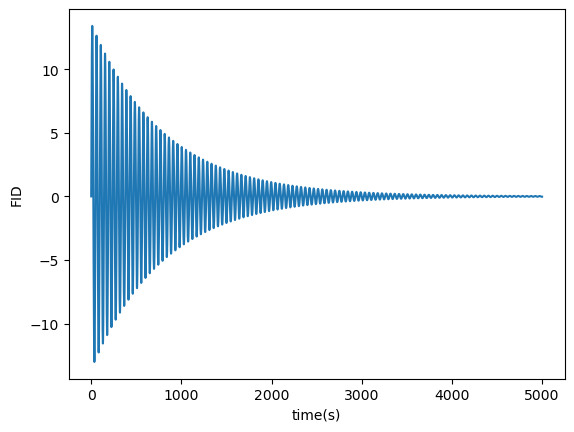

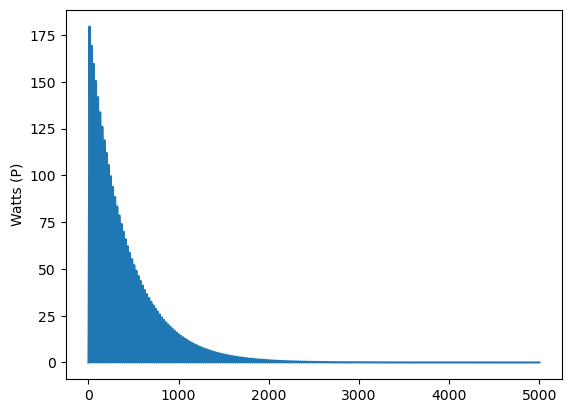

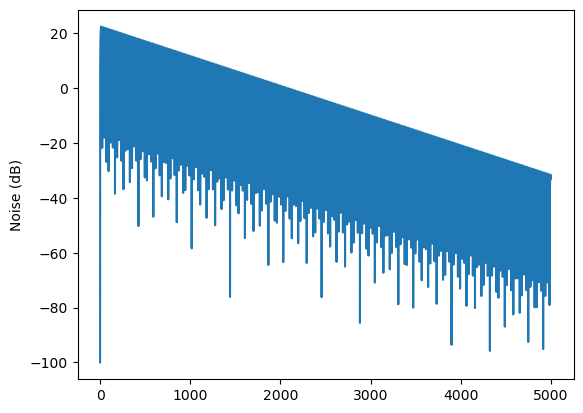

In [156]:
import numpy as np
import matplotlib.pyplot as plt
import random

# i want to create and the FID  raw data to randomly generate an example foi some raw time domain signal i would be seeing. 

Amp = random.randint(50,250)/10
W0 = random.randint(1,1000)/1000
T2 = random.randint(100,1000)
t = np.linspace(0, 5000, 10000)
dt = t[1] - t[0]
fs = 1 / dt

 
FID = Amp*np.sin(W0 * t)*np.exp(-t/(T2)) 
Watts = FID **2
x_db = 10 * np.log10(Watts + 1e-10)

plt.xlabel('time(s)')
plt.ylabel('FID')
plt.plot(t, FID)
plt.show()


plt.ylabel('Watts (P)')
plt.plot(t, Watts)
plt.show()


plt.ylabel('Noise (dB)')
plt.plot(t, x_db)


plt.show()


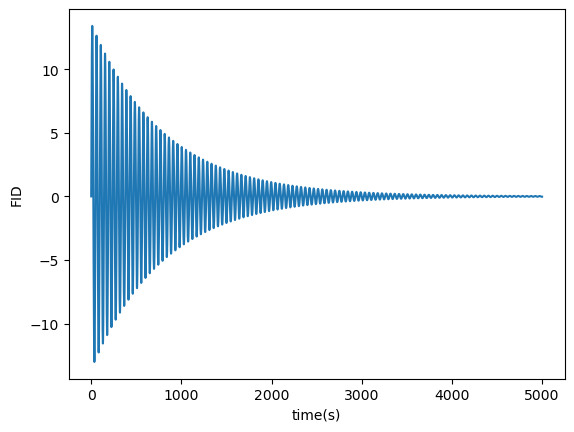

In [157]:

# making random noise and adding it to every random point
target = random.randint(1,1000)/100
avgwatt= np.mean(Watts)
avgdb= 10*np.log10(avgwatt)

noisedb= avgdb-target
noisewatt = 10 ** ( noisedb /10 )

noise_amp = np.sqrt(noisewatt)
noise_array = np.random.normal(0, noise_amp, len(t))
FIDnoise = FID + noise_array


plt.xlabel('time(s)')
plt.ylabel('FID')
plt.plot(t, FID)
plt.show()


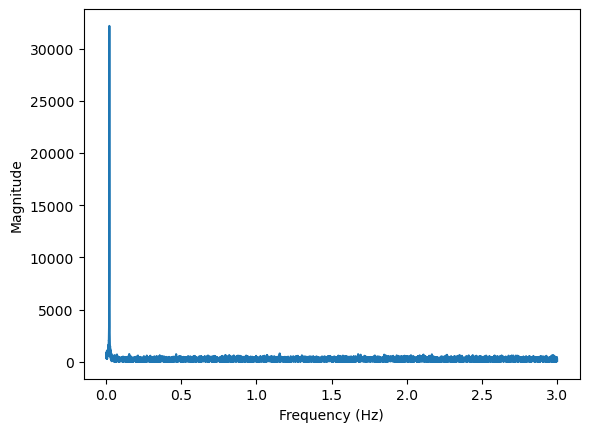

In [158]:
from scipy.fft import fft, fftfreq
from scipy.signal import chirp, find_peaks, peak_widths

N = len(t)
Y = fft(FIDnoise)
freqs = fftfreq(N, dt)
pos_mask = freqs > 0
freqs_pos = freqs[pos_mask]
Y_mag = np.abs(Y[pos_mask])



plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.plot(freqs_pos, Y_mag)
plt.show()


In [159]:
peaks, _ = find_peaks(Y_mag, prominence=np.max(Y_mag) * 0.5)
x_max_positions = freqs_pos[peaks]
y_max_values = Y_mag[peaks]
widths, width_heights, left_ips, right_ips = peak_widths(Y_mag, peaks, rel_height=0.5)

dx = freqs_pos[1] - freqs_pos[0]
fwhms = widths * dx




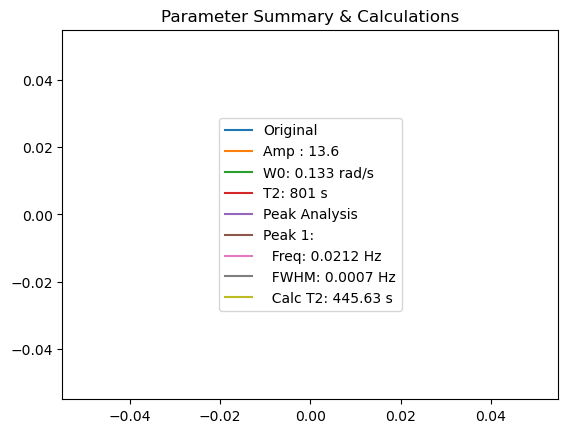

In [160]:
calculated_T2s = 1 / (np.pi * fwhms)
plt.plot([],[],'', label = "Original")
plt.plot([],[],'', label = f"Amp : {Amp}")
plt.plot([],[],'', label = f"W0: {W0} rad/s")
plt.plot([],[],'', label = f"T2: {T2} s")
plt.plot([],[],'', label = "Peak Analysis")
for i in range(len(peaks)):
    plt.plot([],[],'', label = f"Peak {i+1}:")
    plt.plot([],[],'', label = f"  Freq: {x_max_positions[i]:.4f} Hz")
    plt.plot([],[],'', label = f"  FWHM: {fwhms[i]:.4f} Hz")
    plt.plot([],[],'', label = f"  Calc T2: {calculated_T2s[i]:.2f} s")
plt.legend(loc='center')
plt.title("Parameter Summary & Calculations")
plt.show()

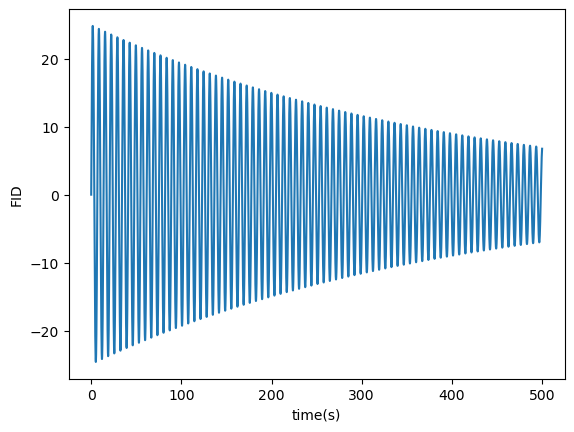

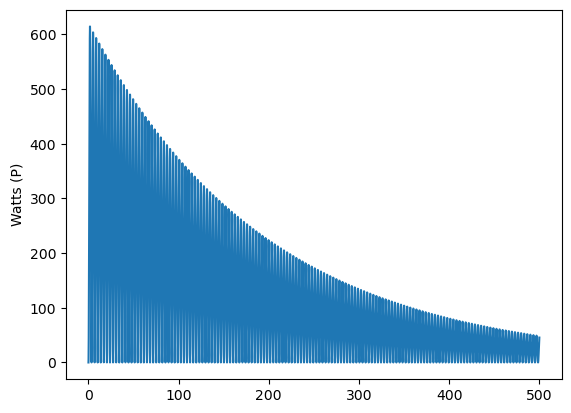

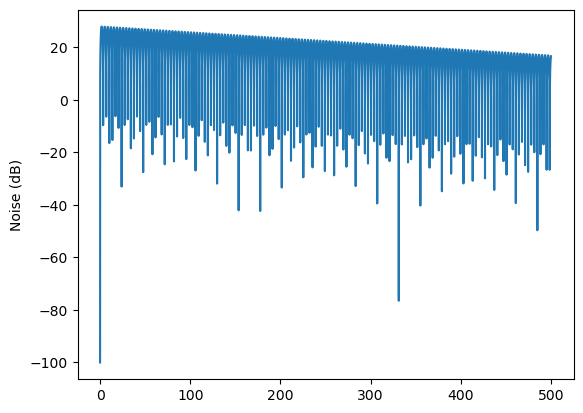

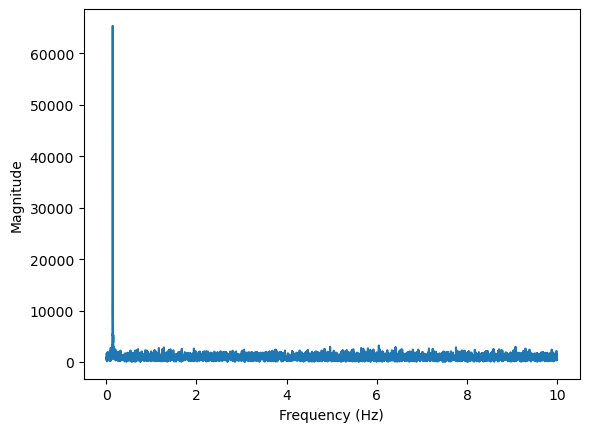

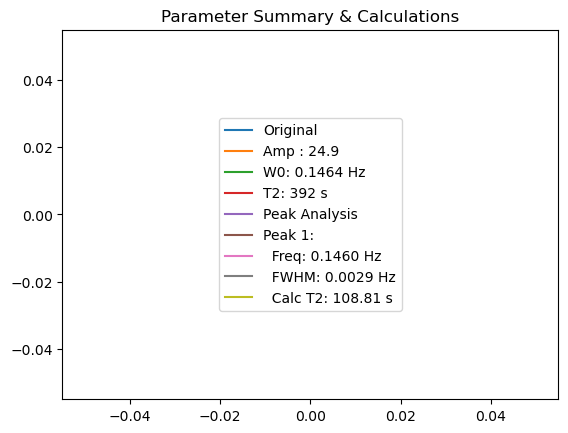

In [176]:
import numpy as np
import matplotlib.pyplot as plt
import random

# i want to create and the FID  raw data to randomly generate an example foi some raw time domain signal i would be seeing. 

Amp = random.randint(50,250)/10
W0 = random.randint(1,1000)/1000
T2 = random.randint(100,1000)
t = np.linspace(0, 500,10000)
dt = t[1] - t[0]
fs = 1 / dt

FID = Amp*np.sin(W0 * t)*np.exp(-t/(T2)) 
Watts = FID **2
x_db = 10 * np.log10(Watts + 1e-10)

plt.xlabel('time(s)')
plt.ylabel('FID')
plt.plot(t, FID)
plt.show()

plt.ylabel('Watts (P)')
plt.plot(t, Watts)
plt.show()

plt.ylabel('Noise (dB)')
plt.plot(t, x_db)
plt.show()

# making random noise and adding it to every random point
target = random.randint(1,1000)/100
avgwatt= np.mean(Watts)
avgdb= 10*np.log10(avgwatt)

noisedb= avgdb-target
noisewatt = 10 ** ( noisedb /10 )

noise_amp = np.sqrt(noisewatt)
noise_array = np.random.normal(0, noise_amp, len(t))
FIDnoise = FID + noise_array

from scipy.fft import fft, fftfreq
from scipy.signal import chirp, find_peaks, peak_widths

N = len(t)
Y = fft(FIDnoise)
freqs = fftfreq(N, dt)
pos_mask = freqs > 0
freqs_pos = freqs[pos_mask]
Y_mag = np.abs(Y[pos_mask])

plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.plot(freqs_pos, Y_mag)
plt.show()

peaks, _ = find_peaks(Y_mag, prominence=np.max(Y_mag) * 0.5)
x_max_positions = freqs_pos[peaks]
y_max_values = Y_mag[peaks]
widths, width_heights, left_ips, right_ips = peak_widths(Y_mag, peaks, rel_height=0.5)

dx = freqs_pos[1] - freqs_pos[0]
fwhms = widths * dx

calculated_T2s = 1 / (np.pi * fwhms)
plt.plot([],[],'', label = "Original")
plt.plot([],[],'', label = f"Amp : {Amp}")
# Converted W0 from rad/s to Hz so it matches the FFT output
plt.plot([],[],'', label = f"W0: {W0 / (2 * np.pi):.4f} Hz")
plt.plot([],[],'', label = f"T2: {T2} s")
plt.plot([],[],'', label = "Peak Analysis")
for i in range(len(peaks)):
    plt.plot([],[],'', label = f"Peak {i+1}:")
    plt.plot([],[],'', label = f"  Freq: {x_max_positions[i]:.4f} Hz")
    plt.plot([],[],'', label = f"  FWHM: {fwhms[i]:.4f} Hz")
    plt.plot([],[],'', label = f"  Calc T2: {calculated_T2s[i]:.2f} s")
plt.legend(loc='center')
plt.title("Parameter Summary & Calculations")
plt.show()

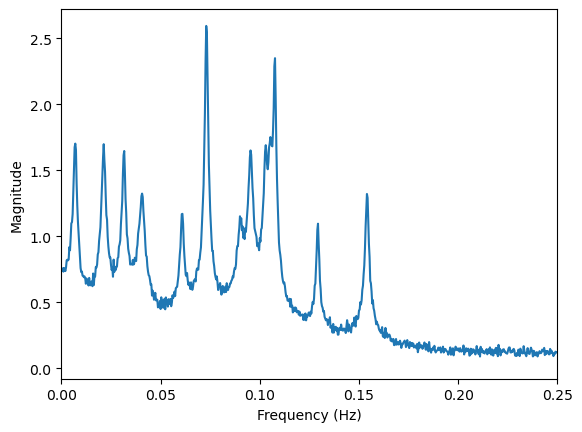


--- GROUND TRUTH ---
              Amplitude  Frequency (Hz)  FWHM (Hz)  T2 (s)
True Peak 1     18.2000          0.0315     0.0016     193
True Peak 2     11.7000          0.0901     0.0023     140
True Peak 3     10.2000          0.0608     0.0014     233
True Peak 4     12.6000          0.1052     0.0018     178
True Peak 5     19.3000          0.1541     0.0017     183
True Peak 6     11.3000          0.1028     0.0014     222
True Peak 7     10.3000          0.1292     0.0013     240
True Peak 8     25.0000          0.0406     0.0029     110
True Peak 9     23.8000          0.0732     0.0015     217
True Peak 10    20.5000          0.1076     0.0013     250
True Peak 11     8.9000          0.0729     0.0016     204
True Peak 12    23.0000          0.0953     0.0022     147
True Peak 13    21.2000          0.0070     0.0018     179
True Peak 14    23.3000          0.0213     0.0020     159

--- CURVE FITTED RESULTS ---
                Amplitude  Frequency (Hz)  FWHM (Hz)  Calc T2 (

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd

pd.set_option('display.float_format', '{:.4f}'.format)

from scipy.fft import fft, fftfreq
from scipy.signal import chirp, find_peaks, peak_widths
from scipy.optimize import curve_fit

def FIDF ():
    Amp = random.randint(50,250)/10
    W0 = random.randint(1,1000)/1000
    T2 = random.randint(100,250)
    t = np.linspace(0, 3000, 60000)
    dt = t[1] - t[0]
    fs = 1 / dt
    
    FID = Amp*np.sin(W0 * t)*np.exp(-t/(T2)) 
    Watts = FID **2
    x_db = 10 * np.log10(Watts + 1e-10)
    target = random.randint(1,1000)/100
    avgwatt= np.mean(Watts)
    avgdb= 10*np.log10(avgwatt)
    
    noisedb= avgdb-target
    noisewatt = 10 ** ( noisedb /10 )
    
    noise_amp = np.sqrt(noisewatt)
    noise_array = np.random.normal(0, noise_amp, len(t))
    FIDnoise = FID + noise_array
    


    N = len(t)
    Y = fft(FIDnoise)

    Y = Y / (N / 2)
    freqs = fftfreq(N, dt)
    pos_mask = freqs > 0
    freqs_pos = freqs[pos_mask]
    Y_mag = np.abs(Y[pos_mask])
    return FID, Y_mag, freqs_pos, Amp, W0, T2

P = random.randint(1,15)
total_Y_mag = 0

ground_truth_freqs = []
ground_truth_fwhms = []
ground_truth_amps = []
ground_truth_T2s = []


for i in range(P):
    FID, Y_mag, freqs_pos, Amp, W0, T2 = FIDF()
    total_Y_mag = total_Y_mag + Y_mag
    exact_freq = W0 / (2 * np.pi)
    exact_fwhm = 1 / (np.pi * T2)    
    ground_truth_freqs.append(exact_freq)
    ground_truth_fwhms.append(exact_fwhm)
    ground_truth_amps.append(Amp)
    ground_truth_T2s.append(T2)

    
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.xlim(0,0.25)
plt.plot(freqs_pos, total_Y_mag) 
plt.show()

def lorentzian(x, Amp, cen, wid):
    return (Amp  * (wid/2)**2 / ((x-cen)**2 +  (wid/2)**2))

def multi_lorentzian (x, *params):
    y = np.zeros_like(x)

    for i in range(0, len(params),3):
        amp = params[i]
        cen = params[i+1]
        wid = params[i+2]
        y +=lorentzian (x, amp, cen, wid)
    return y

peaks, _ = find_peaks(total_Y_mag, prominence=np.max(total_Y_mag) * 0.15)
rough_freqs = freqs_pos[peaks]
rough_amps = total_Y_mag[peaks]
rough_widths_idx, _, _, _ = peak_widths(total_Y_mag, peaks, rel_height=0.5)
dx = freqs_pos[1] - freqs_pos[0]
rough_fwhms = rough_widths_idx * dx

initial_guesses = []
for i in range(len(peaks)):
    initial_guesses.append(rough_amps[i])
    initial_guesses.append(rough_freqs[i])
    initial_guesses.append(rough_fwhms[i])


optimized_params, _ = curve_fit(multi_lorentzian, freqs_pos, total_Y_mag, p0=initial_guesses)

calc_amps = []
calc_freqs = []
calc_fwhms = []
calc_T2s = []

for i in range(0, len(optimized_params), 3):
    freq_amp = optimized_params[i]
    freq = optimized_params[i+1]
    fwhm = optimized_params[i+2]


    calc_T2 = 1 / (np.pi * fwhm)

    time_amp = freq_amp / calc_T2

    calc_amps.append(time_amp)
    calc_freqs.append(freq)
    calc_fwhms.append(fwhm)
    calc_T2s.append(calc_T2)



truth_df = pd.DataFrame({
    'Amplitude': ground_truth_amps,
    'Frequency (Hz)': ground_truth_freqs,
    'FWHM (Hz)': ground_truth_fwhms,
    'T2 (s)': ground_truth_T2s
})
truth_df.index = [f"True Peak {i+1}" for i in range(P)]

print("\n--- GROUND TRUTH ---")
print(truth_df)

detected_df = pd.DataFrame({
    'Amplitude': calc_amps,
    'Frequency (Hz)': calc_freqs,
    'FWHM (Hz)': calc_fwhms,
    'Calc T2 (s)': calc_T2s
})
detected_df.index = [f"Fitted Peak {i+1}" for i in range(len(calc_freqs))]

print("\n--- CURVE FITTED RESULTS ---")
print(detected_df)

In [2]:
def lorentzian(x, Amp, cen, wid):
    return (Amp  * (wid/2)**2 / ((x-cen)**2 +  (wid/2)**2))


def multi_lorentzian (x, params):
    y = np.zeros_like(x)

    for i in range(0, len(params),3):
        amp = params[1]
        cen = params[i+1]
        wid = params[i+2]
        y +=lorentzian (x, amp, cen, wid)
    return y

peaks, _ = find_peaks(total_Y_mag, prominence=np.max(total_Y_mag) * 0.1)
x_max_positions = freqs_pos[peaks]
y_max_values = total_Y_mag[peaks]
widths, width_heights, left_ips, right_ips = peak_widths(total_Y_mag, peaks, rel_height=0.5)

dx = freqs_pos[1] - freqs_pos[0]
fwhms = widths * dx

initial_guesses = []
for i in range(len(peaks)):
    initial_guesses.append(rough_amps[i])
    initial_guesses.append(rough_freqs[i])
    initial_guesses.append(rough_fwhms[i])


optimized_params, _ = curve_fit(multi_lorentzian, freqs_pos, total_Y_mag, p0=initial_guesses)

calc_amps = []
calc_freqs = []
calc_fwhms = []
calc_T2s = []

for i in range(0, len(optimized_params), 3):
    amp = optimized_params[i]
    freq = optimized_params[i+1]
    fwhm = optimized_params[i+2]
    
    calc_amps.append(amp)
    calc_freqs.append(freq)
    calc_fwhms.append(fwhm)
    calc_T2s.append(1 / (np.pi * fwhm))

TypeError: multi_lorentzian() takes 2 positional arguments but 31 were given